In [4]:
import os

print(os.listdir("/kaggle/input"))

['competitions']


In [5]:
import os

print(os.listdir("/kaggle/input/competitions"))

['store-sales-time-series-forecasting']


In [6]:

import os

DATA_DIR = "/kaggle/input/competitions/store-sales-time-series-forecasting"

print(os.listdir(DATA_DIR))


['oil.csv', 'sample_submission.csv', 'holidays_events.csv', 'stores.csv', 'train.csv', 'test.csv', 'transactions.csv']


Dataset loaded successfully!
Dataset shape: (3000888, 6)
   id       date  store_nbr      family  sales  onpromotion
0   0 2013-01-01          1  AUTOMOTIVE    0.0            0
1   1 2013-01-01          1   BABY CARE    0.0            0
2   2 2013-01-01          1      BEAUTY    0.0            0
3   3 2013-01-01          1   BEVERAGES    0.0            0
4   4 2013-01-01          1       BOOKS    0.0            0

Model training completed!
Training rows: 1336
Testing rows: 334
MAE: 77,012.06
RMSE: 120,032.14


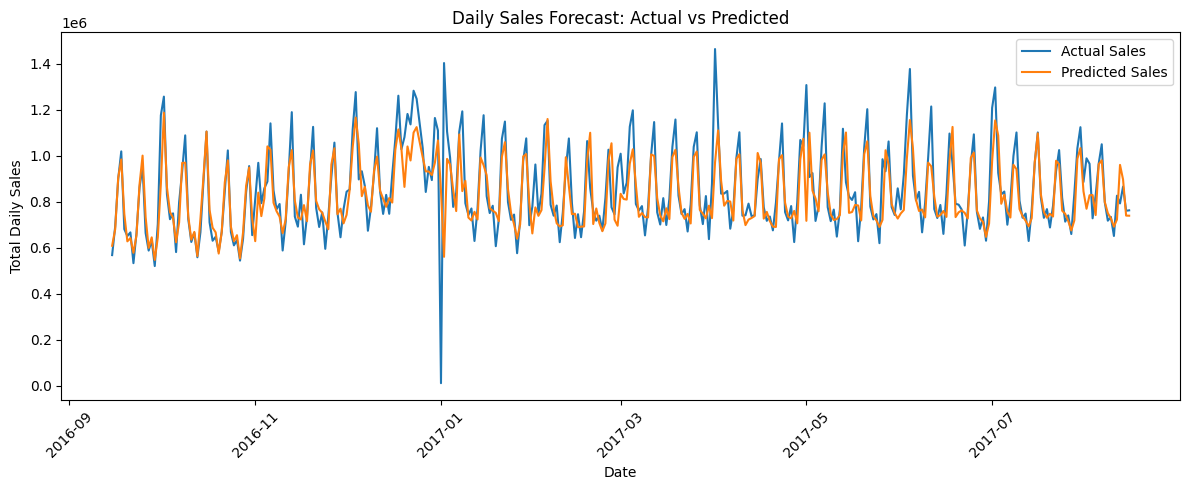


Prediction file saved successfully!
        date  actual_sales  predicted_sales
0 2016-09-15  5.683248e+05    608759.211499
1 2016-09-16  6.919126e+05    680126.446135
2 2016-09-17  8.992193e+05    904731.769877
3 2016-09-18  1.018663e+06    983729.247805
4 2016-09-19  6.811593e+05    746947.085652


In [7]:

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Dataset location
DATA_DIR = "/kaggle/input/competitions/store-sales-time-series-forecasting"

# 2. Load sales data
df = pd.read_csv(f"{DATA_DIR}/train.csv", parse_dates=["date"])

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print(df.head())

# 3. Total sales per day
daily = (
    df.groupby("date", as_index=False)["sales"]
      .sum()
      .sort_values("date")
      .reset_index(drop=True)
)

# 4. Create useful prediction features
daily["day_of_week"] = daily["date"].dt.dayofweek
daily["month"] = daily["date"].dt.month
daily["day_of_year"] = daily["date"].dt.dayofyear

for lag in [1, 7, 14]:
    daily[f"sales_lag_{lag}"] = daily["sales"].shift(lag)

daily["rolling_mean_7"] = (
    daily["sales"].shift(1).rolling(7).mean()
)

daily = daily.dropna().reset_index(drop=True)

# 5. Split chronologically: older data for training,
# newer data for testing
split_index = int(len(daily) * 0.80)

train_data = daily.iloc[:split_index].copy()
test_data = daily.iloc[split_index:].copy()

features = [
    "day_of_week",
    "month",
    "day_of_year",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "rolling_mean_7"
]

X_train = train_data[features]
y_train = train_data["sales"]

X_test = test_data[features]
y_test = test_data["sales"]

# 6. Train machine learning model
model = RandomForestRegressor(
    n_estimators=150,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("\nModel training completed!")

# 7. Make predictions and evaluate
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print(f"MAE: {mae:,.2f}")
print(f"RMSE: {rmse:,.2f}")

# 8. Plot actual vs predicted sales
plt.figure(figsize=(12, 5))
plt.plot(
    test_data["date"], y_test,
    label="Actual Sales"
)
plt.plot(
    test_data["date"], predictions,
    label="Predicted Sales"
)

plt.title("Daily Sales Forecast: Actual vs Predicted")
plt.xlabel("Date")
plt.ylabel("Total Daily Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 9. Save prediction results
results = pd.DataFrame({
    "date": test_data["date"].values,
    "actual_sales": y_test.values,
    "predicted_sales": predictions
})

results.to_csv(
    "/kaggle/working/sample_predictions.csv",
    index=False
)

print("\nPrediction file saved successfully!")
print(results.head())


In [8]:

import os

print(os.listdir("/kaggle/working"))


['.virtual_documents', 'sample_predictions.csv']


In [9]:

import joblib

joblib.dump(model, "/kaggle/working/sales_forecasting_model.joblib")

print("Model saved successfully!")


Model saved successfully!


In [10]:

import os

print(os.listdir("/kaggle/working"))


['.virtual_documents', 'sample_predictions.csv', 'sales_forecasting_model.joblib']


In [11]:

import os
import zipfile

output_dir = "/kaggle/working"
files_to_zip = [
    "sample_predictions.csv",
    "sales_forecasting_model.joblib"
]

zip_path = os.path.join(output_dir, "sales_project_outputs.zip")

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for filename in files_to_zip:
        filepath = os.path.join(output_dir, filename)
        if os.path.exists(filepath):
            z.write(filepath, arcname=filename)
            print("Added:", filename)
        else:
            print("Missing:", filename)

print("ZIP created:", zip_path)


Added: sample_predictions.csv
Added: sales_forecasting_model.joblib
ZIP created: /kaggle/working/sales_project_outputs.zip


In [12]:

from IPython.display import FileLink, display

display(FileLink("/kaggle/working/sales_project_outputs.zip"))


/kaggle/working/sales_project_outputs.zip

In [13]:

import os

for f in os.listdir("/kaggle/working"):
    print(f)


.virtual_documents
sales_project_outputs.zip
sample_predictions.csv
sales_forecasting_model.joblib


In [14]:
from IPython.display import FileLink, display

display(FileLink('/kaggle/working/sales_project_outputs.zip'))

/kaggle/working/sales_project_outputs.zip

In [15]:

from IPython.display import display, FileLink

import os

print(os.path.exists("/kaggle/working/sample_predictions.csv"))
print(os.path.exists("/kaggle/working/sales_forecasting_model.joblib"))


True
True
